# Projeto de Deep Learning — Análise exploratória e de estabilidade

Base **Polish Companies Bankruptcy** (UCI id 365). A leitura e o dicionário de variáveis estão em `01_leitura_dados.ipynb`; aqui a leitura é repetida de forma enxuta para o notebook rodar sozinho.

**Roteiro**
1. Estrutura: duplicados, infinitos, tipos
2. Variável resposta por ano
3. Valores faltantes (por ano e por classe)
4. Distribuições: assimetria, caudas, zeros
5. Poder discriminante univariado (AUC, KS)
6. Correlação e redundância entre indicadores
7. **Estabilidade** entre os 5 horizontes (PSI, KS entre anos, estabilidade da AUC)
8. Resumo por variável
9. Falidas que pareciam saudáveis (bons indicadores, variável a variável, e mesmo assim faliram)

> Os 5 arquivos não são períodos de calendário: o arquivo *k* traz os indicadores do *k*-ésimo ano, com o status de falência (6 − k) anos depois. "Estabilidade" aqui significa: **as distribuições e a relação com a falência se mantêm entre horizontes?** Isso importa para decidir se um único modelo serve para todos os anos ou se cada horizonte precisa do seu.

## Pacotes, leitura e estilo dos gráficos

In [1]:
from pathlib import Path
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.io import arff
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 70)
pd.set_option('display.width', 200)

In [2]:
DADOS = Path('dados')
ZIP = DADOS / 'polish+companies+bankruptcy+data.zip'
ARQUIVOS = {k: DADOS / f'{k}year.arff' for k in range(1, 6)}
if not all(p.exists() for p in ARQUIVOS.values()):
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(DADOS)


def ler_arff(caminho):
    registros, _ = arff.loadarff(caminho)
    df = pd.DataFrame(registros)
    df.columns = [c.replace('Attr', 'X') for c in df.columns]
    df['class'] = df['class'].str.decode('utf-8').astype(int)
    return df


bases = {k: ler_arff(p) for k, p in ARQUIVOS.items()}
df = pd.concat([b.assign(ano=k) for k, b in bases.items()], ignore_index=True)
VARS = [f'X{i}' for i in range(1, 65)]
ANOS = list(range(1, 6))
df.shape

(43405, 66)

In [3]:
# Dicionário resumido (tradução) para rotular tabelas e gráficos
DIC = {
    'X1': 'lucro líquido / ativo total', 'X2': 'passivo total / ativo total', 'X3': 'capital de giro / ativo total',
    'X4': 'ativo circulante / passivo CP', 'X5': 'liquidez em dias (caixa+títulos+receb.-passivo CP)/(desp.op.-depr.)',
    'X6': 'lucros retidos / ativo total', 'X7': 'EBIT / ativo total', 'X8': 'PL contábil / passivo total',
    'X9': 'vendas / ativo total', 'X10': 'PL / ativo total', 'X11': '(lucro bruto+extraord.+desp.fin.) / ativo total',
    'X12': 'lucro bruto / passivo CP', 'X13': '(lucro bruto+depr.) / vendas', 'X14': '(lucro bruto+juros) / ativo total',
    'X15': '(passivo total*365) / (lucro bruto+depr.)', 'X16': '(lucro bruto+depr.) / passivo total',
    'X17': 'ativo total / passivo total', 'X18': 'lucro bruto / ativo total', 'X19': 'lucro bruto / vendas',
    'X20': '(estoque*365) / vendas', 'X21': 'vendas(n) / vendas(n-1)', 'X22': 'lucro operacional / ativo total',
    'X23': 'lucro líquido / vendas', 'X24': 'lucro bruto (3 anos) / ativo total', 'X25': '(PL - capital social) / ativo total',
    'X26': '(lucro líquido+depr.) / passivo total', 'X27': 'lucro operacional / desp. financeiras',
    'X28': 'capital de giro / imobilizado', 'X29': 'log do ativo total', 'X30': '(passivo total - caixa) / vendas',
    'X31': '(lucro bruto+juros) / vendas', 'X32': '(passivo circ.*365) / CPV', 'X33': 'desp. operacionais / passivo CP',
    'X34': 'desp. operacionais / passivo total', 'X35': 'lucro s/ vendas / ativo total', 'X36': 'vendas totais / ativo total',
    'X37': '(ativo circ. - estoques) / passivo LP', 'X38': 'capital permanente / ativo total', 'X39': 'lucro s/ vendas / vendas',
    'X40': '(ativo circ.-estoque-receb.) / passivo CP', 'X41': 'passivo total / ((lucro op.+depr.)*12/365)',
    'X42': 'lucro operacional / vendas', 'X43': 'prazo receb. + giro estoque (dias)', 'X44': '(recebíveis*365) / vendas',
    'X45': 'lucro líquido / estoque', 'X46': '(ativo circ. - estoque) / passivo CP', 'X47': '(estoque*365) / CPV',
    'X48': 'EBITDA / ativo total', 'X49': 'EBITDA / vendas', 'X50': 'ativo circulante / passivo total',
    'X51': 'passivo CP / ativo total', 'X52': '(passivo CP*365) / CPV', 'X53': 'PL / imobilizado',
    'X54': 'capital permanente / imobilizado', 'X55': 'capital de giro (absoluto)', 'X56': '(vendas - CPV) / vendas',
    'X57': '(ativo circ.-estoque-passivo CP) / (vendas-lucro bruto-depr.)', 'X58': 'custos totais / vendas totais',
    'X59': 'passivo LP / PL', 'X60': 'vendas / estoque', 'X61': 'vendas / recebíveis', 'X62': '(passivo CP*365) / vendas',
    'X63': 'vendas / passivo CP', 'X64': 'vendas / imobilizado',
}
assert set(DIC) == set(VARS)

In [4]:
# Estilo: fundo claro, grade discreta, sem bordas superiores/direitas
TINTA, TINTA2, MUDO, GRADE, EIXO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': EIXO, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUDO, 'ytick.color': MUDO, 'text.color': TINTA2, 'legend.frameon': False,
    'figure.dpi': 110, 'lines.linewidth': 2, 'font.size': 10,
})

# Anos são ordinais -> uma rampa sequencial de azul (claro = ano 1, escuro = ano 5)
COR_ANO = dict(zip(ANOS, ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']))
# Classes -> duas cores categóricas fixas
COR_CLASSE = {0: '#2a78d6', 1: '#eb6834'}
NOME_CLASSE = {0: 'não falida', 1: 'falida'}
# Divergente (correlação): laranja <- cinza neutro -> azul
DIVERG = LinearSegmentedColormap.from_list('div', ['#eb6834', '#f0efec', '#2a78d6'])
# Sequencial (PSI, % faltante): um matiz, claro -> escuro
SEQ = LinearSegmentedColormap.from_list('seq', ['#f0efec', '#86b6ef', '#2a78d6', '#104281'])


def slog(x):
    """Log com sinal: comprime as caudas preservando o sinal (útil para razões financeiras)."""
    return np.sign(x) * np.log1p(np.abs(x))

## 1. Estrutura dos dados

In [5]:
estrutura = pd.DataFrame({
    'linhas': df.groupby('ano').size(),
    'duplicadas_no_ano': df.groupby('ano')[VARS + ['class']].apply(lambda g: g.duplicated().sum()),
    'linhas_com_inf': df.groupby('ano')[VARS].apply(lambda g: np.isinf(g).any(axis=1).sum()),
})
estrutura['dup_entre_anos'] = (
    df[df.duplicated(VARS + ['class'], keep=False)]
    .groupby(VARS + ['class'], dropna=False)['ano'].transform('nunique').gt(1)
    .groupby(df['ano']).sum()
).reindex(ANOS, fill_value=0)
estrutura

,linhas,duplicadas_no_ano,linhas_com_inf,dup_entre_anos
ano,,,,
1,7027,82,0,0
2,10173,90,0,0
3,10503,87,0,0
4,9792,82,0,0
5,5910,60,0,0


In [6]:
# Valores constantes ou quase constantes
nunicos = df[VARS].nunique()
prop_zero = (df[VARS] == 0).mean()
pd.DataFrame({'n_unicos': nunicos, '%_zeros': (prop_zero * 100).round(1)}).sort_values('%_zeros', ascending=False).head(10)

,n_unicos,%_zeros
X59,22266,43.8
X6,23548,41.3
X42,33981,9.2
X22,33462,9.2
X27,34178,6.8
X47,34136,4.9
X20,33907,4.7
X48,37940,2.0
X49,38212,1.9
X57,36837,1.2


## 2. Variável resposta

In [7]:
resp = df.groupby('ano')['class'].agg(n='size', falidas='sum')
resp['taxa_%'] = (resp['falidas'] / resp['n'] * 100).round(2)
resp['razao_desbalanceamento'] = ((resp['n'] - resp['falidas']) / resp['falidas']).round(1)
resp

,n,falidas,taxa_%,razao_desbalanceamento
ano,,,,
1,7027,271,3.86,24.9
2,10173,400,3.93,24.4
3,10503,495,4.71,20.2
4,9792,515,5.26,18.0
5,5910,410,6.94,13.4


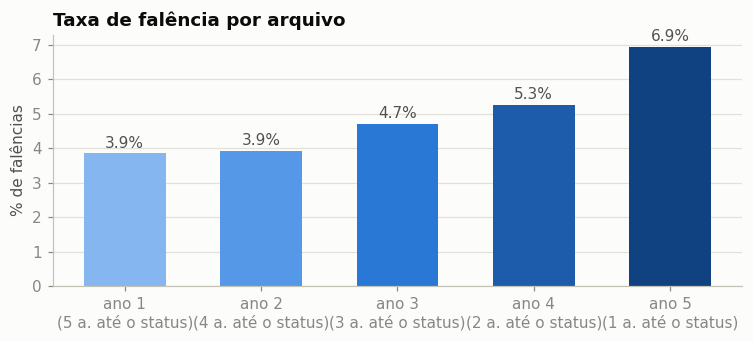

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
barras = ax.bar(resp.index, resp['taxa_%'], color=[COR_ANO[a] for a in resp.index], width=0.6)
for b, v in zip(barras, resp['taxa_%']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.15, f'{v:.1f}%', ha='center', color=TINTA2)
ax.set_xticks(ANOS, [f'ano {a}\n({6 - a} a. até o status)' for a in ANOS])
ax.set_ylabel('% de falências')
ax.set_title('Taxa de falência por arquivo')
ax.grid(axis='x', visible=False)
plt.tight_layout()

A taxa cresce à medida que o horizonte encurta (empresas mais próximas da falência). O desbalanceamento (entre 13:1 e 25:1) exige métricas como AUC/PR-AUC, *class weights* ou reamostragem na rede.

## 3. Valores faltantes

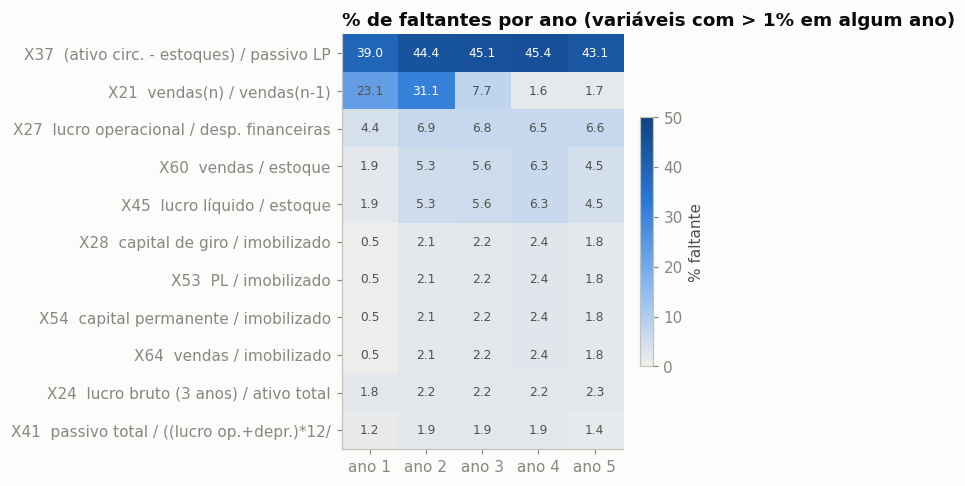

In [9]:
falt = df.groupby('ano')[VARS].apply(lambda g: g.isna().mean() * 100).T
falt_top = falt[falt.max(axis=1) > 1].sort_values(3, ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(falt_top) + 1))
im = ax.imshow(falt_top.values, cmap=SEQ, aspect='auto', vmin=0, vmax=50)
ax.set_xticks(range(5), [f'ano {a}' for a in ANOS])
ax.set_yticks(range(len(falt_top)), [f'{v}  {DIC[v][:38]}' for v in falt_top.index])
for i in range(falt_top.shape[0]):
    for j in range(5):
        v = falt_top.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8, color='white' if v > 25 else TINTA2)
ax.grid(False)
ax.set_title('% de faltantes por ano (variáveis com > 1% em algum ano)')
plt.colorbar(im, ax=ax, shrink=0.6, label='% faltante')
plt.tight_layout()

In [10]:
# O faltante é informativo? Compara % faltante entre falidas e não falidas
falt_classe = df.groupby('class')[VARS].apply(lambda g: g.isna().mean() * 100).T
falt_classe.columns = ['%_na_nao_falida', '%_na_falida']
falt_classe['diferenca_pp'] = falt_classe['%_na_falida'] - falt_classe['%_na_nao_falida']
falt_classe['descricao'] = falt_classe.index.map(DIC)
falt_classe.round(2).sort_values('diferenca_pp', key=abs, ascending=False).head(12)

,%_na_nao_falida,%_na_falida,diferenca_pp,descricao
X27,4.96,34.19,29.23,lucro operacional / desp. financeiras
X21,12.68,29.41,16.73,vendas(n) / vendas(n-1)
X45,4.77,8.42,3.65,lucro líquido / estoque
X60,4.78,8.42,3.63,vendas / estoque
X37,43.59,46.72,3.14,(ativo circ. - estoques) / passivo LP
X24,2.23,0.05,-2.18,lucro bruto (3 anos) / ativo total
X54,1.77,3.83,2.05,capital permanente / imobilizado
X28,1.77,3.83,2.05,capital de giro / imobilizado
X53,1.77,3.83,2.05,PL / imobilizado
X64,1.77,3.83,2.05,vendas / imobilizado


## 4. Distribuições

In [11]:
desc = pd.DataFrame({
    'mediana': df[VARS].median(),
    'p1': df[VARS].quantile(.01),
    'p99': df[VARS].quantile(.99),
    'min': df[VARS].min(),
    'max': df[VARS].max(),
    'assimetria': df[VARS].skew(),
    'curtose': df[VARS].kurt(),
})
# fração de valores fora de [p1 - 3*IQR, p99 + 3*IQR]: caudas extremas
q1, q3 = df[VARS].quantile(.25), df[VARS].quantile(.75)
iqr = q3 - q1
desc['%_extremos'] = (((df[VARS] < q1 - 3 * iqr) | (df[VARS] > q3 + 3 * iqr)).mean() * 100).round(2)
desc.round(3).sort_values('curtose', ascending=False).head(15)

,mediana,p1,p99,min,max,assimetria,curtose,%_extremos
X56,0.053,-0.663,0.987,-1.108300e+06,293.15,-207.991,43266.243,5.14
X20,35.150,0.000,274.385,-2.934000e+01,7809200.00,207.913,43244.268,1.98
X58,0.951,0.048,1.658,-1.986900e+02,1108300.00,207.047,43009.819,5.20
X41,0.086,-2.202,7.492,-1.234400e+03,288770.00,206.265,42579.864,10.00
X43,99.402,9.691,659.646,-1.158700e+05,30393000.00,203.545,41975.718,2.39
X44,54.768,2.958,441.419,-1.158700e+05,22584000.00,200.253,40990.762,2.71
X49,0.011,-0.868,0.382,-9.001000e+03,178.89,-184.565,36520.470,5.85
X59,0.006,-2.657,6.402,-3.279700e+02,23853.00,177.762,33906.961,10.35
X61,6.636,0.610,97.640,-1.265600e+01,108000.00,176.212,33748.263,5.30
X5,-1.034,-2978.500,2879.175,-1.190300e+07,1250100.00,-171.776,33058.497,8.89


Praticamente todas as razões têm caudas muito pesadas (curtose na casa de milhares), consequência de denominadores próximos de zero. Para a rede neural a padronização simples (média/desvio) não basta: é recomendável **winsorizar** (ex.: p1–p99) ou aplicar o **log com sinal** / `QuantileTransformer` antes de padronizar.

Os gráficos abaixo usam o log com sinal, `sign(x)·log(1+|x|)`, para tornar as distribuições legíveis.

## 5. Poder discriminante univariado

In [12]:
def auc_var(x, y):
    m = x.notna()
    if y[m].nunique() < 2:
        return np.nan
    return roc_auc_score(y[m], x[m])


def ks_classes(x, y):
    m = x.notna()
    return stats.ks_2samp(x[m & (y == 1)], x[m & (y == 0)]).statistic


auc = pd.DataFrame({a: {v: auc_var(bases[a][v], bases[a]['class']) for v in VARS} for a in ANOS})
ks = pd.DataFrame({a: {v: ks_classes(bases[a][v], bases[a]['class']) for v in VARS} for a in ANOS})

poder = pd.DataFrame({
    'descricao': pd.Series(DIC),
    'AUC_geral': {v: auc_var(df[v], df['class']) for v in VARS},
    'KS_medio': ks.mean(axis=1),
})
poder['forca'] = (poder['AUC_geral'] - 0.5).abs()
poder['direcao'] = np.where(poder['AUC_geral'] > 0.5, 'maior → mais falência', 'menor → mais falência')
poder = poder.sort_values('forca', ascending=False)
poder.round(3).head(20)

,descricao,AUC_geral,KS_medio,forca,direcao
X26,(lucro líquido+depr.) / passivo total,0.277,0.367,0.223,menor → mais falência
X16,(lucro bruto+depr.) / passivo total,0.279,0.366,0.221,menor → mais falência
X13,(lucro bruto+depr.) / vendas,0.286,0.346,0.214,menor → mais falência
X46,(ativo circ. - estoque) / passivo CP,0.298,0.333,0.202,menor → mais falência
X12,lucro bruto / passivo CP,0.301,0.341,0.199,menor → mais falência
X24,lucro bruto (3 anos) / ativo total,0.301,0.360,0.199,menor → mais falência
X23,lucro líquido / vendas,0.306,0.325,0.194,menor → mais falência
X19,lucro bruto / vendas,0.307,0.321,0.193,menor → mais falência
X31,(lucro bruto+juros) / vendas,0.312,0.312,0.188,menor → mais falência
X45,lucro líquido / estoque,0.312,0.317,0.188,menor → mais falência


AUC univariada calculada nas linhas sem faltante. AUC > 0,5: valores **maiores** associados a falência; AUC < 0,5: valores **menores** associados a falência. A coluna `forca = |AUC − 0,5|` ordena as variáveis independentemente da direção.

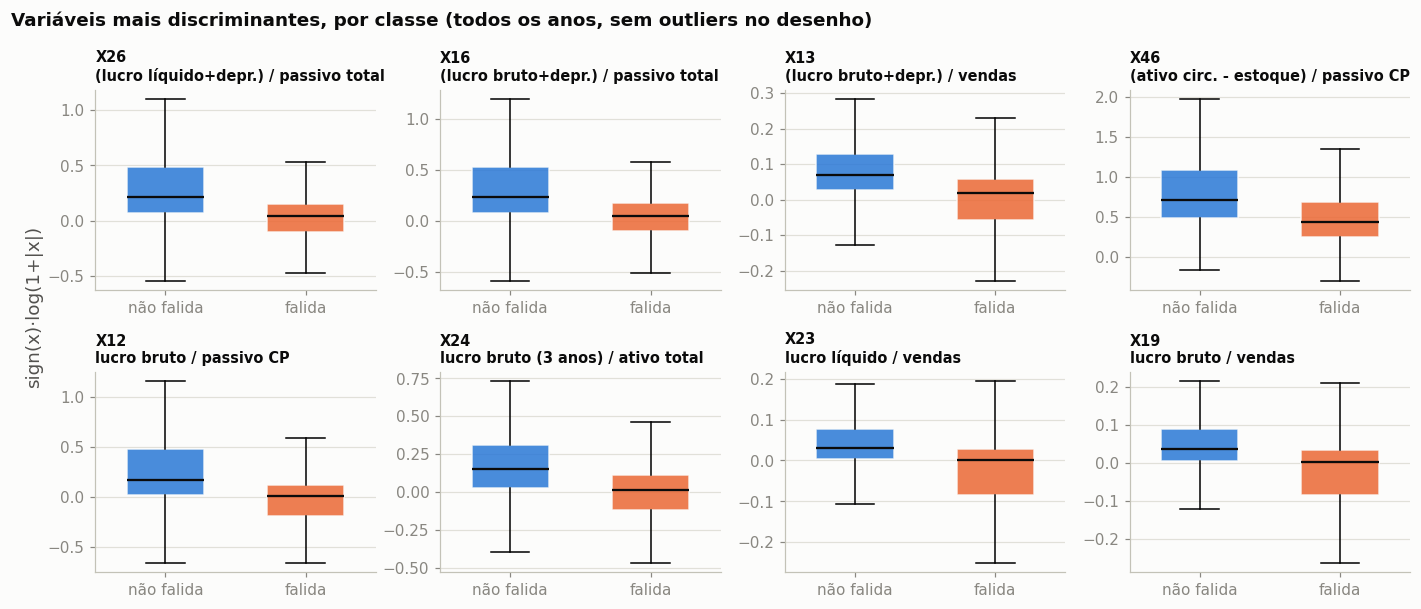

In [13]:
TOP = poder.index[:8].tolist()

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=False)
for ax, v in zip(axes.flat, TOP):
    dados = [slog(df.loc[df['class'] == c, v].dropna()).clip(-8, 8) for c in (0, 1)]
    bp = ax.boxplot(dados, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=TINTA, linewidth=1.5))
    for patch, c in zip(bp['boxes'], (0, 1)):
        patch.set(facecolor=COR_CLASSE[c], alpha=0.85, edgecolor='#fcfcfb')
    ax.set_xticks([1, 2], [NOME_CLASSE[0], NOME_CLASSE[1]])
    ax.set_title(f'{v}\n{DIC[v][:40]}', fontsize=9.5)
    ax.grid(axis='x', visible=False)
fig.supylabel('sign(x)·log(1+|x|)', color=TINTA2)
fig.suptitle('Variáveis mais discriminantes, por classe (todos os anos, sem outliers no desenho)',
             x=0.01, ha='left', fontweight='bold', color=TINTA)
plt.tight_layout()

## 6. Correlação e redundância

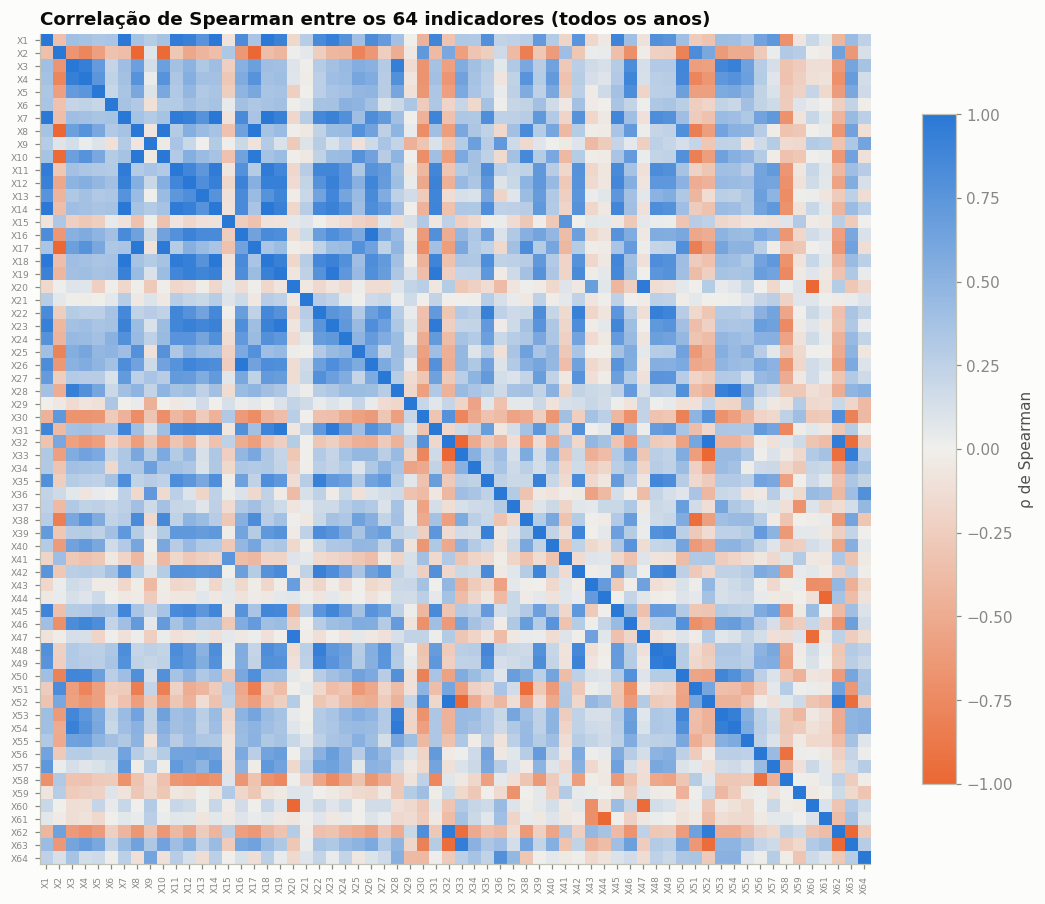

In [14]:
corr = df[VARS].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap=DIVERG, vmin=-1, vmax=1)
ax.set_xticks(range(64), VARS, rotation=90, fontsize=6)
ax.set_yticks(range(64), VARS, fontsize=6)
ax.grid(False)
ax.set_title('Correlação de Spearman entre os 64 indicadores (todos os anos)')
plt.colorbar(im, ax=ax, shrink=0.7, label='ρ de Spearman')
plt.tight_layout()

In [15]:
# Pares quase redundantes (|ρ| ≥ 0,95)
sup = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares = sup[sup.abs() >= 0.95].sort_values(key=abs, ascending=False).rename('rho').reset_index()
pares.columns = ['var_a', 'var_b', 'rho']
pares['desc_a'] = pares['var_a'].map(DIC)
pares['desc_b'] = pares['var_b'].map(DIC)
print(f'{len(pares)} pares com |ρ| ≥ 0,95')
pares.round(3)

35 pares com |ρ| ≥ 0,95


,var_a,var_b,rho,desc_a,desc_b
0,X14,X18,1.000,(lucro bruto+juros) / ativo total,lucro bruto / ativo total
1,X7,X14,1.000,EBIT / ativo total,(lucro bruto+juros) / ativo total
2,X20,X60,-1.000,(estoque*365) / vendas,vendas / estoque
3,X7,X18,1.000,EBIT / ativo total,lucro bruto / ativo total
4,X2,X17,-1.000,passivo total / ativo total,ativo total / passivo total
5,X62,X63,-0.999,(passivo CP*365) / vendas,vendas / passivo CP
6,X44,X61,-0.999,(recebíveis*365) / vendas,vendas / recebíveis
7,X32,X52,0.998,(passivo circ.*365) / CPV,(passivo CP*365) / CPV
8,X33,X52,-0.998,desp. operacionais / passivo CP,(passivo CP*365) / CPV
9,X32,X33,-0.997,(passivo circ.*365) / CPV,desp. operacionais / passivo CP


In [16]:
# Grupos de variáveis redundantes (componentes conexas do grafo |ρ| ≥ 0,95)
grupos, visto = [], set()
adj = {v: set() for v in VARS}
for a, b in zip(pares['var_a'], pares['var_b']):
    adj[a].add(b); adj[b].add(a)
for v in VARS:
    if v in visto or not adj[v]:
        continue
    pilha, comp = [v], set()
    while pilha:
        u = pilha.pop()
        if u not in comp:
            comp.add(u); pilha.extend(adj[u] - comp)
    visto |= comp
    grupos.append(sorted(comp, key=lambda s: int(s[1:])))
for g in grupos:
    print(' , '.join(f'{v} ({DIC[v]})' for v in g))

X1 (lucro líquido / ativo total) , X7 (EBIT / ativo total) , X11 ((lucro bruto+extraord.+desp.fin.) / ativo total) , X14 ((lucro bruto+juros) / ativo total) , X18 (lucro bruto / ativo total)
X2 (passivo total / ativo total) , X8 (PL contábil / passivo total) , X10 (PL / ativo total) , X17 (ativo total / passivo total)
X16 ((lucro bruto+depr.) / passivo total) , X26 ((lucro líquido+depr.) / passivo total)
X19 (lucro bruto / vendas) , X23 (lucro líquido / vendas) , X31 ((lucro bruto+juros) / vendas)
X20 ((estoque*365) / vendas) , X47 ((estoque*365) / CPV) , X60 (vendas / estoque)
X28 (capital de giro / imobilizado) , X54 (capital permanente / imobilizado)
X32 ((passivo circ.*365) / CPV) , X33 (desp. operacionais / passivo CP) , X52 ((passivo CP*365) / CPV) , X62 ((passivo CP*365) / vendas) , X63 (vendas / passivo CP)
X38 (capital permanente / ativo total) , X51 (passivo CP / ativo total)
X44 ((recebíveis*365) / vendas) , X61 (vendas / recebíveis)
X48 (EBITDA / ativo total) , X49 (EBITDA 

## 7. Análise de estabilidade

Três perguntas:

1. **Estabilidade da distribuição** — as variáveis têm a mesma distribuição nos 5 horizontes? Medida pelo **PSI** (*Population Stability Index*) contra o ano de referência, e pela estatística D do teste KS entre anos.
2. **Estabilidade da composição** — parte da mudança vem só de haver mais falidas nos anos finais? Recalcula-se o PSI só com as não falidas.
3. **Estabilidade da relação com a resposta** — a AUC univariada se mantém entre anos? Há inversão de direção?

### 7.1 PSI

$$\text{PSI} = \sum_{i}(p_i^{\text{novo}} - p_i^{\text{ref}})\,\ln\frac{p_i^{\text{novo}}}{p_i^{\text{ref}}}$$

Faixas usuais: **< 0,10 estável**, **0,10–0,25 mudança moderada**, **> 0,25 mudança relevante**. Bins = decis da referência + um bin próprio para faltantes (assim mudanças na taxa de faltantes também entram no índice). Referência: **ano 1**, o primeiro horizonte.

In [17]:
def psi(ref, novo, n_bins=10, eps=1e-4):
    ref, novo = pd.Series(ref), pd.Series(novo)
    cortes = np.unique(np.nanquantile(ref.dropna(), np.linspace(0, 1, n_bins + 1)[1:-1]))
    cortes = np.concatenate([[-np.inf], cortes, [np.inf]])

    def props(s):
        cont = pd.cut(s.dropna(), cortes, include_lowest=True).value_counts(sort=False).values
        cont = np.append(cont, s.isna().sum())  # bin de faltantes
        return np.clip(cont / len(s), eps, None)

    p, q = props(ref), props(novo)
    return float(np.sum((q - p) * np.log(q / p)))


REF = 1
psi_tab = pd.DataFrame({a: {v: psi(bases[REF][v], bases[a][v]) for v in VARS} for a in ANOS if a != REF})
psi_tab.columns = [f'ano {a}' for a in psi_tab.columns]

# PSI entre anos consecutivos (deriva passo a passo)
psi_consec = pd.DataFrame({f'{a}→{a + 1}': {v: psi(bases[a][v], bases[a + 1][v]) for v in VARS} for a in ANOS[:-1]})

# PSI só com não falidas (remove o efeito da taxa de falência crescente)
nf = {a: bases[a][bases[a]['class'] == 0] for a in ANOS}
psi_nf = pd.DataFrame({f'ano {a}': {v: psi(nf[REF][v], nf[a][v]) for v in VARS} for a in ANOS if a != REF})


def faixa(x):
    return 'estável' if x < 0.10 else ('moderada' if x <= 0.25 else 'relevante')


contagem = pd.DataFrame({c: psi_tab[c].map(faixa).value_counts() for c in psi_tab}).reindex(
    ['estável', 'moderada', 'relevante']).fillna(0).astype(int)
contagem

,ano 2,ano 3,ano 4,ano 5
estável,49,47,45,56
moderada,14,16,18,7
relevante,1,1,1,1


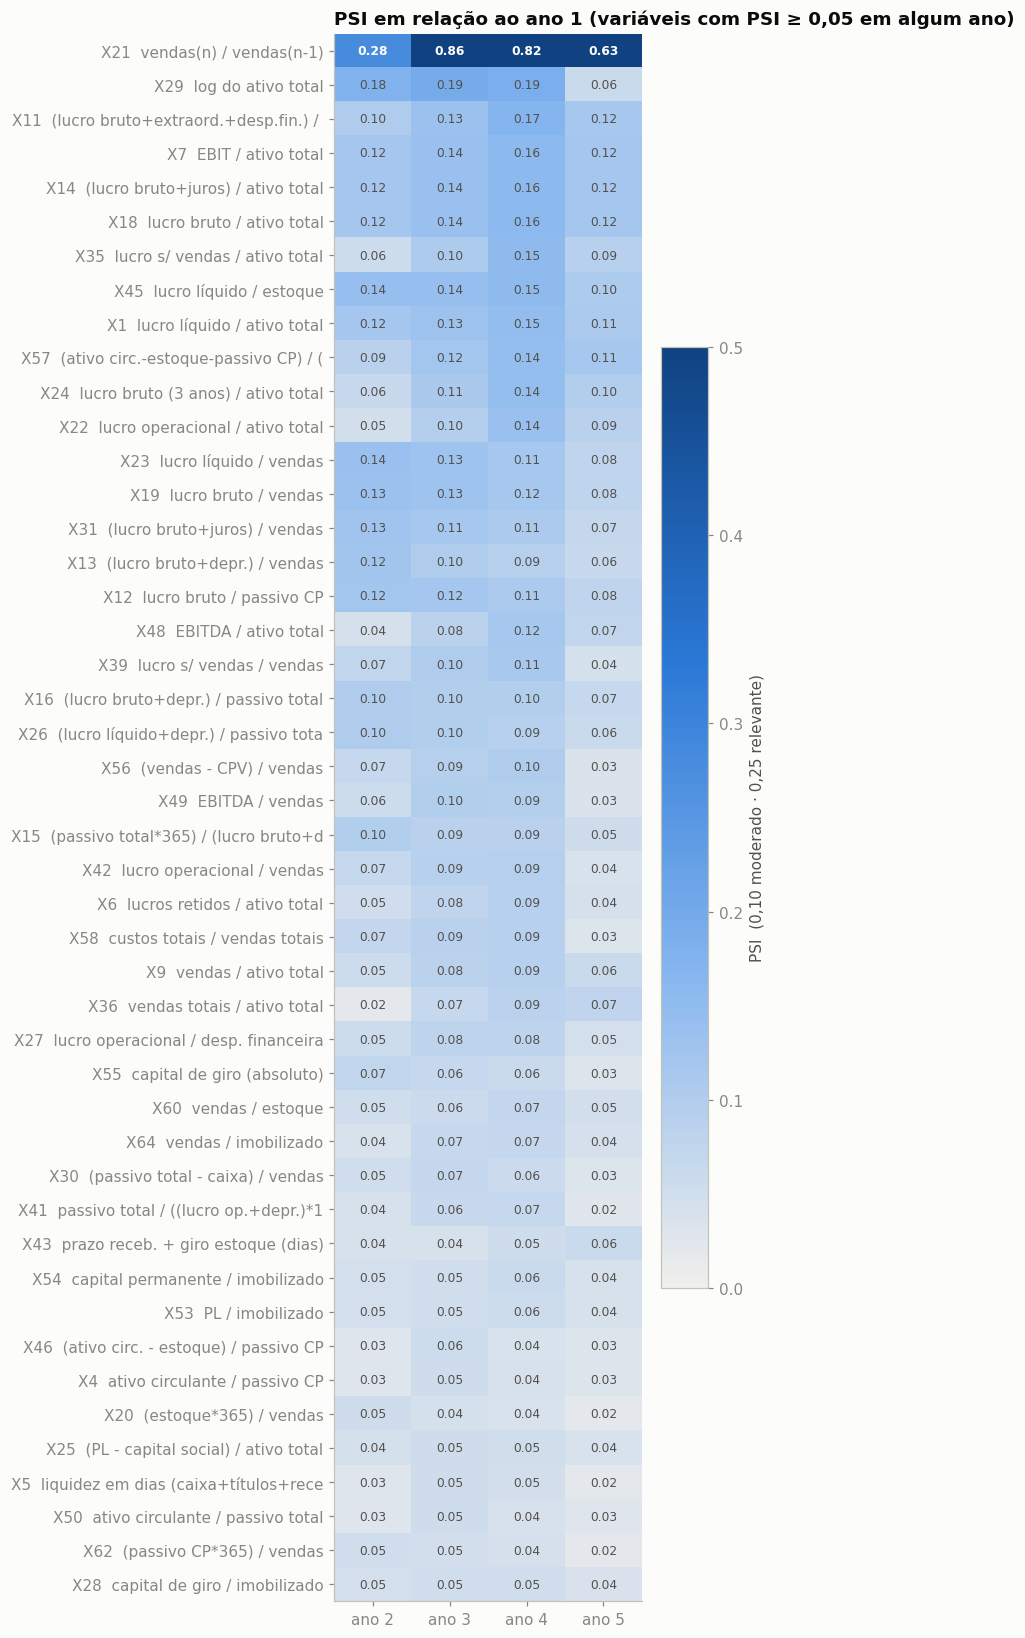

In [18]:
ordem = psi_tab.max(axis=1).sort_values(ascending=False)
mostrar = ordem[ordem >= 0.05].index  # só o que mexe; o resto é < 0,05 em todos os anos

fig, ax = plt.subplots(figsize=(6.8, 0.3 * len(mostrar) + 1.2))
im = ax.imshow(psi_tab.loc[mostrar].values, cmap=SEQ, aspect='auto', vmin=0, vmax=0.5)
ax.set_xticks(range(psi_tab.shape[1]), psi_tab.columns)
ax.set_yticks(range(len(mostrar)), [f'{v}  {DIC[v][:36]}' for v in mostrar])
for i, v in enumerate(mostrar):
    for j, c in enumerate(psi_tab.columns):
        val = psi_tab.loc[v, c]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8,
                color='white' if val > 0.25 else TINTA2, fontweight='bold' if val > 0.25 else 'normal')
ax.grid(False)
ax.set_title(f'PSI em relação ao ano {REF} (variáveis com PSI ≥ 0,05 em algum ano)')
plt.colorbar(im, ax=ax, shrink=0.6, label='PSI  (0,10 moderado · 0,25 relevante)')
plt.tight_layout()

In [19]:
# Consecutivo e só não falidas, para as mesmas variáveis
pd.concat({'PSI vs ano 1': psi_tab.loc[mostrar], 'PSI consecutivo': psi_consec.loc[mostrar],
           'PSI vs ano 1 (só não falidas)': psi_nf.loc[mostrar]}, axis=1).round(3)

PSI vs ano 1                      PSI consecutivo                      PSI vs ano 1 (só não falidas)                     
           ano 2  ano 3  ano 4  ano 5             1→2    2→3    3→4    4→5                         ano 2  ano 3  ano 4  ano 5
X21        0.280  0.863  0.817  0.632           0.280  0.541  0.285  0.100                         0.294  0.903  1.082  1.352
X29        0.176  0.194  0.186  0.062           0.176  0.001  0.004  0.068                         0.179  0.194  0.180  0.052
X11        0.101  0.133  0.169  0.116           0.101  0.016  0.016  0.009                         0.083  0.108  0.142  0.083
X7         0.118  0.136  0.158  0.118           0.118  0.016  0.010  0.006                         0.119  0.132  0.151  0.095
X14        0.118  0.136  0.157  0.118           0.118  0.016  0.010  0.006                         0.119  0.132  0.151  0.095
X18        0.118  0.136  0.157  0.118           0.118  0.016  0.010  0.006                         0.119  0.131  0.151  0.095
X35        0.055  0.104  0.153  0.090           0.055  0.013  0.013  0.020                         0.056  0.098  0.144  0.069
X45        0.141  0.141  0.153  0.105           0.141  0.005  0.008  0.012                         0.151  0.140  0.145  0.080
X1         0.118  0.130  0.146  0.108           0.118  0.012  0.009  0.005                         0.122  0.126  0.139  0.084
X57        0.086  0.120  0.143  0.114           0.086  0.013  0.009  0.010                         0.092  0.124  0.148  0.119
X24        0.063  0.111  0.143  0.097           0.063  0.021  0.007  0.008                         0.065  0.106  0.130  0.068
X22        0.047  0.095  0.136  0.086           0.047  0.014  0.012  0.012                         0.037  0.073  0.113  0.069
X23        0.135  0.129  0.114  0.075           0.135  0.006  0.005  0.011                         0.140  0.121  0.103  0.045
X19        0.134  0.127  0.117  0.076           0.134  0.006  0.004  0.012                         0.140  0.121  0.107  0.049
X31        0.126  0.114  0.106  0.070           0.126  0.009  0.004  0.011                         0.133  0.111  0.099  0.045
X13        0.122  0.103  0.093  0.064           0.122  0.005  0.004  0.011                         0.123  0.096  0.079  0.037
X12        0.121  0.117  0.109  0.076           0.121  0.007  0.010  0.005                         0.127  0.114  0.100  0.047
X48        0.042  0.082  0.115  0.073           0.042  0.012  0.013  0.015                         0.042  0.079  0.111  0.063
X39        0.073  0.101  0.112  0.044           0.073  0.010  0.008  0.025                         0.075  0.095  0.100  0.023
X16        0.103  0.097  0.097  0.068           0.103  0.005  0.006  0.005                         0.103  0.088  0.082  0.039
X26        0.102  0.097  0.090  0.062           0.102  0.004  0.006  0.004                         0.104  0.088  0.079  0.037
X56        0.068  0.093  0.101  0.035           0.068  0.010  0.010  0.029                         0.066  0.087  0.090  0.016
X49        0.056  0.096  0.094  0.034           0.056  0.014  0.008  0.021                         0.056  0.093  0.089  0.022
X15        0.096  0.088  0.086  0.054           0.096  0.006  0.007  0.005                         0.098  0.081  0.070  0.028
X42        0.066  0.090  0.094  0.037           0.066  0.010  0.008  0.021                         0.057  0.069  0.066  0.017
X6         0.052  0.075  0.089  0.042           0.052  0.006  0.004  0.015                         0.054  0.072  0.083  0.024
X58        0.071  0.087  0.089  0.033           0.071  0.006  0.006  0.021                         0.070  0.081  0.079  0.017
X9         0.055  0.084  0.088  0.060           0.055  0.013  0.005  0.023                         0.054  0.078  0.082  0.058
X36        0.019  0.067  0.086  0.075           0.019  0.021  0.003  0.014                         0.019  0.068  0.087  0.081
X27        0.055  0.079  0.078  0.045           0.055  0.009  0.003  0.029                        

### 7.2 KS entre anos

Estatística D do teste de Kolmogorov–Smirnov (máxima distância entre as distribuições acumuladas) de cada ano contra o ano 1. Com dezenas de milhares de linhas qualquer diferença é "significativa" — por isso olhamos o **tamanho** de D, não o p-valor. Regra prática: D < 0,05 desprezível, D > 0,10 diferença perceptível.

In [20]:
ks_anos = pd.DataFrame({f'ano {a}': {v: stats.ks_2samp(bases[REF][v].dropna(), bases[a][v].dropna()).statistic
                                      for v in VARS} for a in ANOS if a != REF})
ks_anos['D_max'] = ks_anos.max(axis=1)
ks_anos.sort_values('D_max', ascending=False).head(12).round(3)

,ano 2,ano 3,ano 4,ano 5,D_max
X21,0.260,0.386,0.208,0.070,0.386
X29,0.156,0.167,0.161,0.074,0.167
X57,0.112,0.149,0.165,0.151,0.165
X7,0.130,0.154,0.163,0.133,0.163
X14,0.130,0.154,0.163,0.133,0.163
X18,0.130,0.154,0.163,0.133,0.163
X1,0.128,0.146,0.156,0.127,0.156
X11,0.104,0.137,0.156,0.121,0.156
X35,0.092,0.127,0.150,0.107,0.150
X22,0.080,0.123,0.146,0.108,0.146


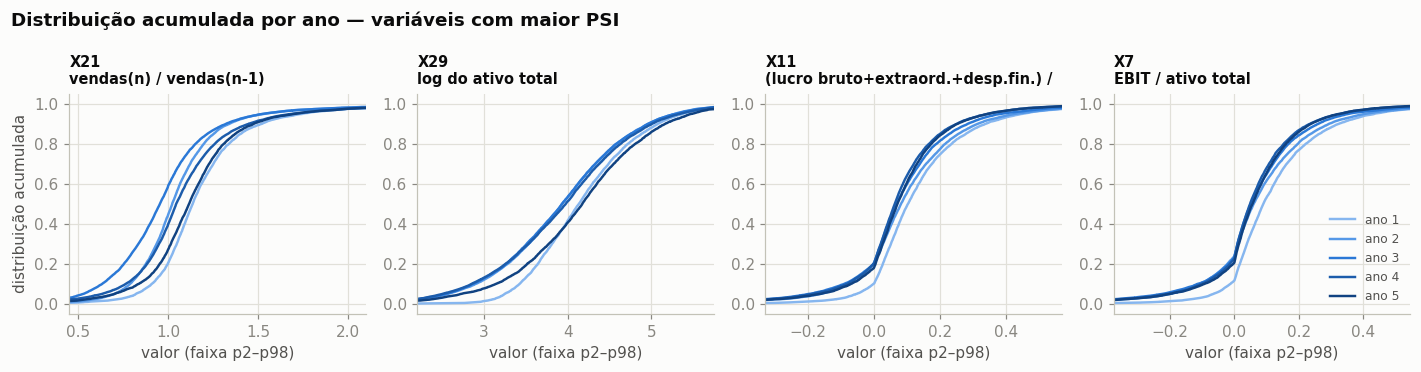

In [21]:
# Quantis das variáveis menos estáveis ao longo dos anos
inst = ordem.index[:4].tolist()
fig, axes = plt.subplots(1, len(inst), figsize=(13, 3.4))
for ax, v in zip(axes, inst):
    lo, hi = df[v].quantile([.02, .98])
    for a in ANOS:
        xs = np.sort(bases[a][v].dropna())
        ax.plot(xs, np.linspace(0, 1, len(xs)), color=COR_ANO[a], linewidth=1.6, label=f'ano {a}')
    ax.set_xlim(lo, hi)
    ax.set_title(f'{v}\n{DIC[v][:36]}', fontsize=9.5)
    ax.set_xlabel('valor (faixa p2–p98)')
axes[0].set_ylabel('distribuição acumulada')
axes[-1].legend(loc='lower right', fontsize=8)
fig.suptitle('Distribuição acumulada por ano — variáveis com maior PSI', x=0.01, ha='left', fontweight='bold', color=TINTA)
plt.tight_layout()

### 7.3 Estabilidade do poder discriminante

Para cada variável: AUC univariada em cada ano, desvio-padrão entre anos e se a **direção** da relação (AUC acima ou abaixo de 0,5) muda. Inversão só é preocupante quando a variável tem força relevante em ao menos um dos anos.

In [22]:
auc_est = auc.copy()
auc_est.columns = [f'ano {a}' for a in ANOS]
auc_est['media'] = auc.mean(axis=1)
auc_est['desvio'] = auc.std(axis=1)
auc_est['amplitude'] = auc.max(axis=1) - auc.min(axis=1)
lado = np.sign(auc - 0.5).where((auc - 0.5).abs() >= 0.03)  # ignora AUC ~ 0,5
auc_est['inverte_direcao'] = lado.apply(lambda r: r.dropna().nunique() > 1, axis=1)
auc_est['descricao'] = auc_est.index.map(DIC)
auc_est.round(3).sort_values('amplitude', ascending=False).head(15)

,ano 1,ano 2,ano 3,ano 4,ano 5,media,desvio,amplitude,inverte_direcao,descricao
X21,0.436,0.500,0.496,0.405,0.260,0.419,0.098,0.240,False,vendas(n) / vendas(n-1)
X15,0.555,0.536,0.496,0.428,0.329,0.469,0.092,0.226,True,(passivo total*365) / (lucro bruto+depr.)
X41,0.545,0.519,0.498,0.426,0.326,0.463,0.088,0.219,True,passivo total / ((lucro op.+depr.)*12/365)
X27,0.505,0.473,0.418,0.392,0.287,0.415,0.084,0.218,False,lucro operacional / desp. financeiras
X45,0.326,0.390,0.325,0.309,0.216,0.313,0.063,0.174,False,lucro líquido / estoque
X35,0.371,0.381,0.338,0.327,0.219,0.327,0.064,0.161,False,lucro s/ vendas / ativo total
X39,0.354,0.370,0.327,0.318,0.211,0.316,0.062,0.158,False,lucro s/ vendas / vendas
X29,0.464,0.489,0.466,0.425,0.334,0.436,0.061,0.155,False,log do ativo total
X23,0.302,0.382,0.315,0.304,0.227,0.306,0.055,0.155,False,lucro líquido / vendas
X19,0.305,0.382,0.317,0.304,0.229,0.308,0.055,0.154,False,lucro bruto / vendas


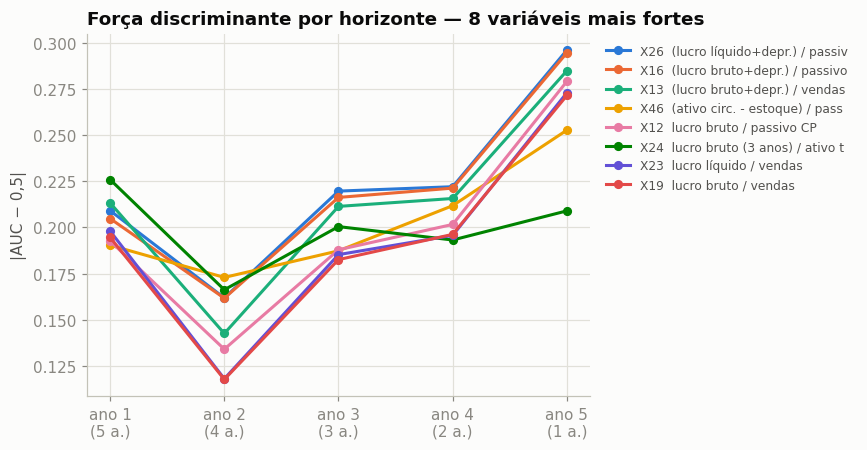

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.2))
forca = (auc - 0.5).abs()
top_forca = forca.mean(axis=1).sort_values(ascending=False).index[:8]
cores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
for v, c in zip(top_forca, cores):
    ax.plot(ANOS, forca.loc[v], marker='o', markersize=5, color=c, label=f'{v}  {DIC[v][:30]}')
ax.set_xticks(ANOS, [f'ano {a}\n({6 - a} a.)' for a in ANOS])
ax.set_ylabel('|AUC − 0,5|')
ax.set_title('Força discriminante por horizonte — 8 variáveis mais fortes')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()

Esperado: o poder discriminante cresce do ano 1 (status 5 anos depois) para o ano 5 (status 1 ano depois) — sinais de deterioração financeira ficam mais nítidos perto da falência. Isso é uma mudança na **relação** X → y entre horizontes, não apenas na distribuição de X.

## 8. Resumo por variável

In [24]:
resumo = pd.DataFrame({
    'descricao': pd.Series(DIC),
    '%_faltante': (df[VARS].isna().mean() * 100).round(1),
    'AUC_geral': poder['AUC_geral'].round(3),
    'forca': poder['forca'].round(3),
    'PSI_max': psi_tab.max(axis=1).round(3),
    'PSI_max_nao_falidas': psi_nf.max(axis=1).round(3),
    'KS_anos_max': ks_anos['D_max'].round(3),
    'AUC_desvio_anos': auc_est['desvio'].round(3),
    'inverte_direcao': auc_est['inverte_direcao'],
})
redundante_com = {}
for g in grupos:
    for v in g:
        redundante_com[v] = ', '.join(x for x in g if x != v)
resumo['redundante_com'] = pd.Series(redundante_com)
resumo['estabilidade'] = resumo['PSI_max'].map(faixa)
resumo['alerta'] = np.select(
    [resumo['%_faltante'] > 20, resumo['PSI_max'] > 0.25, resumo['inverte_direcao'] & (resumo['forca'] > 0.05)],
    ['muitos faltantes', 'distribuição instável', 'relação instável'], default='')
resumo.sort_values('forca', ascending=False)

,descricao,%_faltante,AUC_geral,forca,PSI_max,PSI_max_nao_falidas,KS_anos_max,AUC_desvio_anos,inverte_direcao,redundante_com,estabilidade,alerta
X26,(lucro líquido+depr.) / passivo total,0.2,0.277,0.223,0.102,0.104,0.114,0.048,False,X16,moderada,
X16,(lucro bruto+depr.) / passivo total,0.2,0.279,0.221,0.103,0.103,0.118,0.048,False,X26,moderada,
X13,(lucro bruto+depr.) / vendas,0.3,0.286,0.214,0.122,0.123,0.117,0.050,False,NaN,moderada,
X46,(ativo circ. - estoque) / passivo CP,0.3,0.298,0.202,0.056,0.057,0.071,0.031,False,NaN,estável,
X12,lucro bruto / passivo CP,0.3,0.301,0.199,0.121,0.127,0.134,0.052,False,NaN,moderada,
...,...,...,...,...,...,...,...,...,...,...,...,...
X47,(estoque*365) / CPV,0.7,0.480,0.020,0.033,0.033,0.061,0.022,False,"X20, X60",estável,
X36,vendas totais / ativo total,0.0,0.517,0.017,0.086,0.087,0.122,0.007,False,NaN,estável,
X20,(estoque*365) / vendas,0.3,0.514,0.014,0.055,0.054,0.055,0.015,False,"X47, X60",estável,
X43,prazo receb. + giro estoque (dias),0.3,0.510,0.010,0.061,0.065,0.098,0.014,False,NaN,estável,


In [25]:
# Para usar no pré-processamento / modelagem
resumo.to_csv('resumo_variaveis.csv', encoding='utf-8-sig')
resumo['estabilidade'].value_counts()

estabilidade
estável      42
moderada     21
relevante     1
Name: count, dtype: int64

## 9. Falidas que pareciam saudáveis

Havia empresas com **bons indicadores** que mesmo assim faliram? A análise é feita **variável a variável**: para cada indicador, quantas falidas tinham um valor **melhor do que a mediana das não falidas** (e melhor do que o percentil 75, ou seja, melhor do que 3 em cada 4 empresas que não faliram). "Melhor" segue a direção da seção 5: nas variáveis "menor → mais falência", melhor é maior; nas outras, melhor é menor.

Depois, uma regra contábil simples com 4 indicadores, o perfil das falidas que passam nela e se os modelos finais conseguem encontrá-las.

### 9.1 Variável a variável

In [26]:
VAR9 = list(dict.fromkeys(poder.index[:8].tolist() + ['X1', 'X2', 'X3', 'X4']))
nf_, f_ = df[df['class'] == 0], df[df['class'] == 1]


def pct_melhor(v, q, base_f=f_, base_nf=nf_):
    """% das falidas (com valor observado) melhores do que o quantil q das não falidas."""
    x = base_f[v].dropna()
    if poder.loc[v, 'AUC_geral'] < 0.5:  # menor -> mais falência: melhor = maior
        return (x > base_nf[v].quantile(q)).mean() * 100
    return (x < base_nf[v].quantile(1 - q)).mean() * 100


var_a_var = pd.DataFrame({
    'descricao': [DIC[v] for v in VAR9],
    'melhor é': ['maior' if poder.loc[v, 'AUC_geral'] < 0.5 else 'menor' for v in VAR9],
    'mediana não falidas': [nf_[v].median() for v in VAR9],
    'mediana falidas': [f_[v].median() for v in VAR9],
    '% falidas melhores que a mediana das não falidas': [pct_melhor(v, 0.50) for v in VAR9],
    '% falidas melhores que o p75 das não falidas': [pct_melhor(v, 0.75) for v in VAR9],
}, index=VAR9)
var_a_var.round(3)

,descricao,melhor é,mediana não falidas,mediana falidas,% falidas melhores que a mediana das não falidas,% falidas melhores que o p75 das não falidas
X26,(lucro líquido+depr.) / passivo total,maior,0.235,0.041,18.936,8.102
X16,(lucro bruto+depr.) / passivo total,maior,0.260,0.046,19.175,8.293
X13,(lucro bruto+depr.) / vendas,maior,0.071,0.018,20.962,8.558
X46,(ativo circ. - estoque) / passivo CP,maior,1.053,0.543,23.417,10.509
X12,lucro bruto / passivo CP,maior,0.185,0.010,21.295,8.921
X24,lucro bruto (3 anos) / ativo total,maior,0.164,0.013,20.526,10.144
X23,lucro líquido / vendas,maior,0.032,0.002,22.308,9.519
X19,lucro bruto / vendas,maior,0.038,0.003,23.365,10.000
X1,lucro líquido / ativo total,maior,0.053,0.003,24.258,12.632
X2,passivo total / ativo total,menor,0.462,0.669,25.407,11.675


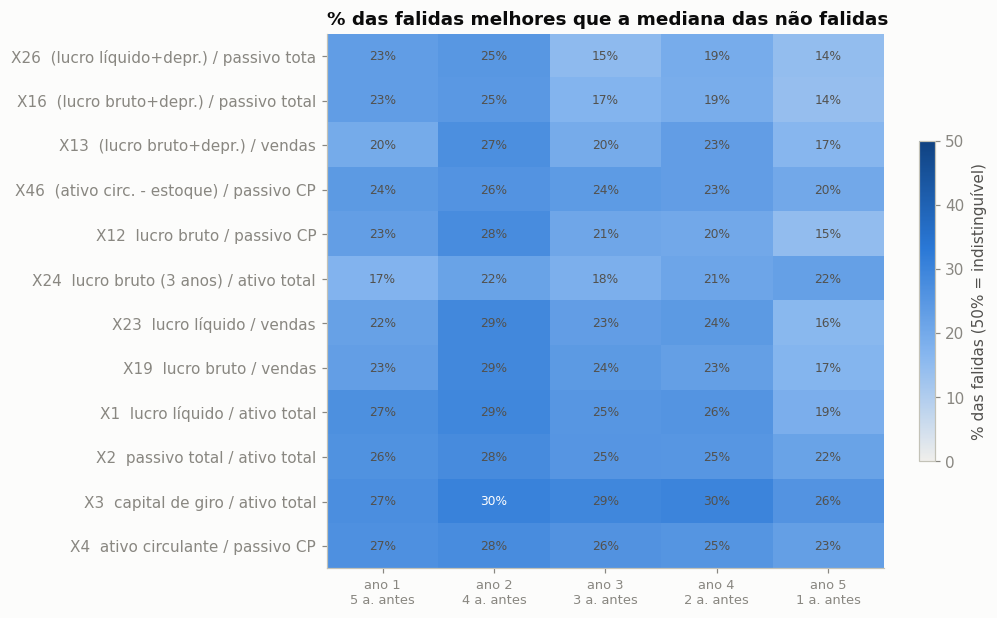

In [27]:
# Por arquivo: % das falidas melhores que a mediana das não falidas do mesmo arquivo
pm_ano = pd.DataFrame({
    f'ano {a}': {v: pct_melhor(v, 0.50, df[(df['ano'] == a) & (df['class'] == 1)], df[(df['ano'] == a) & (df['class'] == 0)])
                 for v in VAR9} for a in ANOS})

fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(VAR9) + 1.4))
im = ax.imshow(pm_ano.values, cmap=SEQ, aspect='auto', vmin=0, vmax=50)
ax.set_xticks(range(5), [f'ano {a}\n{6 - a} a. antes' for a in ANOS], fontsize=8.5)
ax.set_yticks(range(len(VAR9)), [f'{v}  {DIC[v][:36]}' for v in VAR9])
for i in range(pm_ano.shape[0]):
    for j in range(5):
        val = pm_ano.values[i, j]
        ax.text(j, i, f'{val:.0f}%', ha='center', va='center', fontsize=8, color='white' if val > 30 else TINTA2)
ax.grid(False)
ax.set_title('% das falidas melhores que a mediana das não falidas')
plt.colorbar(im, ax=ax, shrink=0.6, label='% das falidas (50% = indistinguível)')
plt.tight_layout()

Se uma variável não tivesse nenhuma relação com a falência, 50% das falidas estariam acima da mediana das não falidas. Quanto mais longe de 50%, mais a variável separa; o que sobra (as falidas do lado "bom") são as que aquela variável sozinha não pega.

### 9.2 Regra contábil com 4 indicadores

Uma empresa "parece saudável" se tem, ao mesmo tempo, lucro líquido positivo (X1 > 0), capital de giro positivo (X3 > 0), liquidez corrente acima de 1,2 (X4 > 1,2) e passivo abaixo de 60% do ativo (X2 < 0,6).

In [28]:
REGRAS = {
    'lucro > 0 (X1)': df['X1'] > 0,
    'capital de giro > 0 (X3)': df['X3'] > 0,
    'liquidez corrente > 1,2 (X4)': df['X4'] > 1.2,
    'passivo < 60% do ativo (X2)': df['X2'] < 0.6,
}
regra = pd.DataFrame(REGRAS)
regra['todas as 4'] = regra.all(axis=1)

tab_regra = (regra.groupby(df['class']).mean().T * 100).round(1)
tab_regra.columns = ['% não falidas', '% falidas']
tab_regra

,% não falidas,% falidas
lucro > 0 (X1),79.2,54.1
capital de giro > 0 (X3),78.9,56.8
"liquidez corrente > 1,2 (X4)",67.7,42.1
passivo < 60% do ativo (X2),66.7,41.0
todas as 4,49.8,19.5


,% não falidas que passam,% falidas que passam,falidas que passam (n),falidas (n)
ano,,,,
1,51.7,23.2,63,271
2,47.6,23.8,95,400
3,48.4,18.6,92,495
4,49.2,19.6,101,515
5,54.9,13.7,56,410


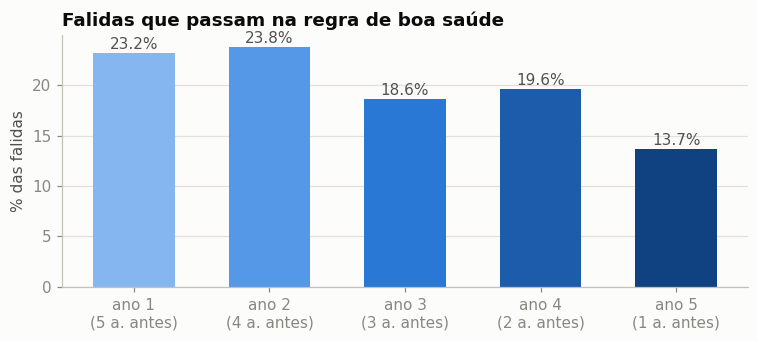

In [29]:
# "Todas as 4" por arquivo
g = regra['todas as 4'].groupby([df['ano'], df['class']])
por_ano = pd.DataFrame({
    '% não falidas que passam': (g.mean().xs(0, level='class') * 100).round(1),
    '% falidas que passam': (g.mean().xs(1, level='class') * 100).round(1),
    'falidas que passam (n)': g.sum().xs(1, level='class').astype(int),
    'falidas (n)': df[df['class'] == 1].groupby('ano').size(),
})

fig, ax = plt.subplots(figsize=(7, 3.2))
barras = ax.bar(ANOS, por_ano['% falidas que passam'], color=[COR_ANO[a] for a in ANOS], width=0.6)
for b, v in zip(barras, por_ano['% falidas que passam']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f'{v:.1f}%', ha='center', color=TINTA2)
ax.set_xticks(ANOS, [f'ano {a}\n({6 - a} a. antes)' for a in ANOS])
ax.set_ylabel('% das falidas')
ax.set_title('Falidas que passam na regra de boa saúde')
ax.grid(axis='x', visible=False)
plt.tight_layout()
por_ano

Quantas das 4 regras cada empresa cumpre? Se a regra fosse suficiente, a taxa de falência cairia a zero entre as que cumprem todas.

,taxa de falência,empresas,falidas
0,0.138,3415,472
1,0.083,5234,437
2,0.060,5553,334
3,0.054,8218,441
4,0.019,20985,407


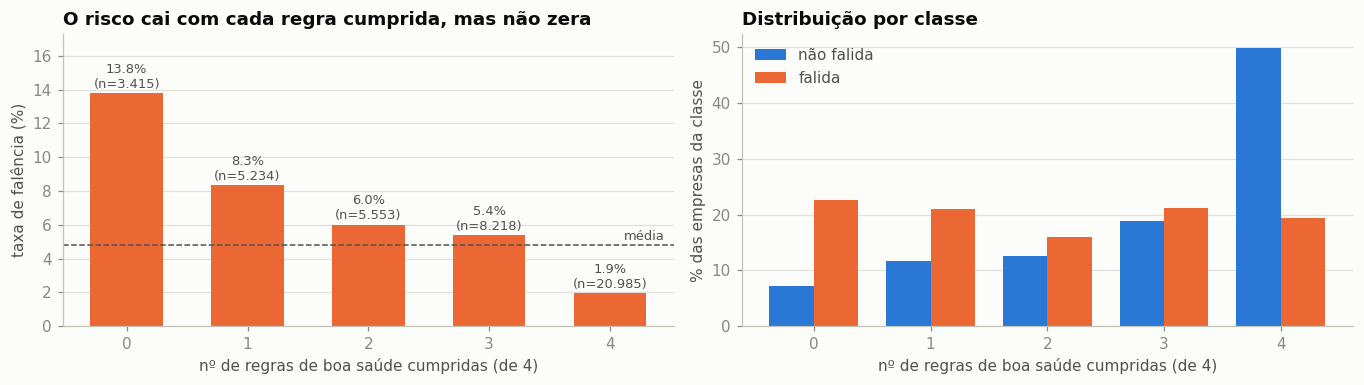

In [30]:
n_regras = regra[list(REGRAS)].sum(axis=1)
taxa_n = df['class'].groupby(n_regras).agg(['mean', 'size', 'sum'])
dist_n = pd.crosstab(n_regras, df['class'], normalize='columns') * 100

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
barras = axes[0].bar(taxa_n.index, taxa_n['mean'] * 100, color='#eb6834', width=0.6)
for b, (t, n) in zip(barras, zip(taxa_n['mean'] * 100, taxa_n['size'])):
    axes[0].text(b.get_x() + b.get_width() / 2, t + 0.3, f'{t:.1f}%\n(n={n:,})'.replace(',', '.'), ha='center',
                 fontsize=8.5, color=TINTA2)
axes[0].axhline(df['class'].mean() * 100, color=TINTA2, linestyle='--', linewidth=1)
axes[0].text(4.45, df['class'].mean() * 100 + 0.3, 'média', fontsize=8.5, color=TINTA2, ha='right')
axes[0].set_xticks(range(5))
axes[0].set_xlabel('nº de regras de boa saúde cumpridas (de 4)')
axes[0].set_ylabel('taxa de falência (%)')
axes[0].set_ylim(0, taxa_n['mean'].max() * 100 * 1.25)
axes[0].set_title('O risco cai com cada regra cumprida, mas não zera')
axes[0].grid(axis='x', visible=False)

larg = 0.38
for k, c in enumerate((0, 1)):
    axes[1].bar(dist_n.index + (k - 0.5) * larg, dist_n[c], width=larg, color=COR_CLASSE[c], label=NOME_CLASSE[c])
axes[1].set_xticks(range(5))
axes[1].set_xlabel('nº de regras de boa saúde cumpridas (de 4)')
axes[1].set_ylabel('% das empresas da classe')
axes[1].set_title('Distribuição por classe')
axes[1].legend()
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
taxa_n.rename(columns={'mean': 'taxa de falência', 'size': 'empresas', 'sum': 'falidas'}).round(3)

### 9.3 Perfil das falidas que passam na regra

In [31]:
df['grupo'] = np.select(
    [df['class'] == 0, (df['class'] == 1) & regra['todas as 4']],
    ['não falida', 'falida "saudável"'], default='falida típica')
ordem_g = ['não falida', 'falida "saudável"', 'falida típica']
cols = list(dict.fromkeys(['X1', 'X2', 'X3', 'X4', 'X9', 'X21', 'X27', 'X29'] + poder.index[:8].tolist()))
perfil = df.groupby('grupo')[cols].median().T[ordem_g]
perfil.insert(0, 'descricao', perfil.index.map(DIC))
extra = pd.DataFrame({
    'n': df.groupby('grupo').size(),
    'faltantes por linha (média)': df[VARS].isna().sum(axis=1).groupby(df['grupo']).mean(),
    '% com X27 faltante': df['X27'].isna().groupby(df['grupo']).mean() * 100,
}).T[ordem_g]
display(perfil.round(3))
extra.round(2)

grupo,descricao,não falida,"falida ""saudável""",falida típica
X1,lucro líquido / ativo total,0.053,0.085,-0.027
X2,passivo total / ativo total,0.462,0.363,0.745
X3,capital de giro / ativo total,0.204,0.367,-0.021
X4,ativo circulante / passivo CP,1.603,2.159,0.958
X9,vendas / ativo total,1.197,1.206,1.106
X21,vendas(n) / vendas(n-1),1.047,1.043,0.963
X27,lucro operacional / desp. financeiras,1.092,8.807,-0.149
X29,log do ativo total,4.021,3.842,3.885
X26,(lucro líquido+depr.) / passivo total,0.235,0.402,0.003
X16,(lucro bruto+depr.) / passivo total,0.260,0.469,0.004


grupo,não falida,"falida ""saudável""",falida típica
n,41314.00,407.00,1684.00
faltantes por linha (média),0.92,1.85,1.50
% com X27 faltante,4.96,39.80,32.84


Onde essas falidas ficam no mapa de rentabilidade × endividamento? E o que as diferencia das não falidas, se não são os indicadores?

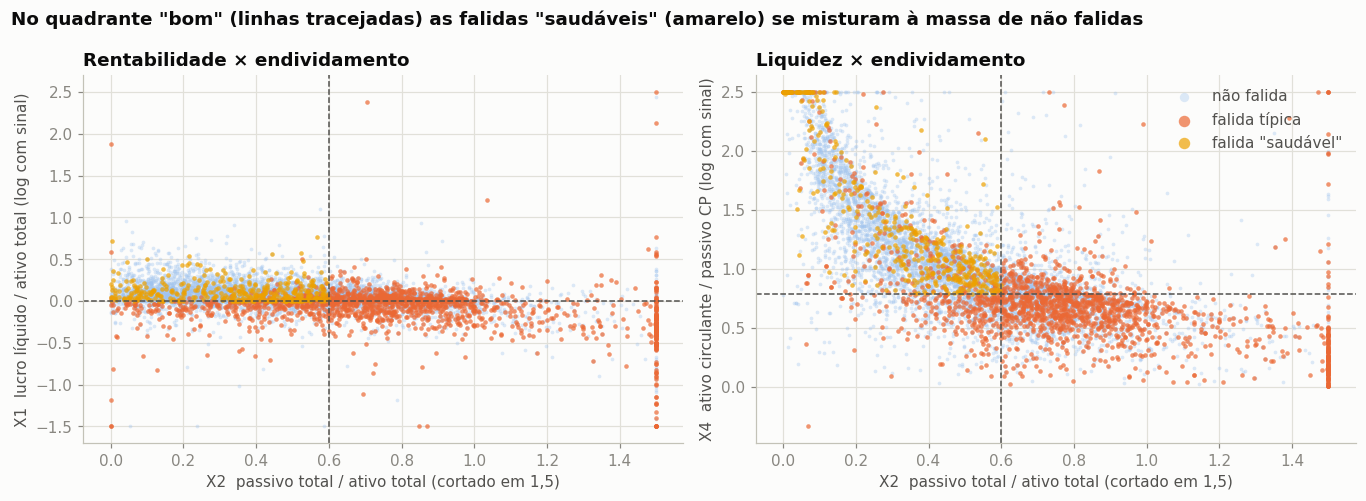

In [32]:
COR_GRUPO = {'não falida': '#9fc3ee', 'falida "saudável"': '#eda100', 'falida típica': '#eb6834'}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
amostra_nf = df[df['grupo'] == 'não falida'].sample(6000, random_state=0)
for ax, (vx, vy) in zip(axes, [('X2', 'X1'), ('X2', 'X4')]):
    for gnome, base in [('não falida', amostra_nf), ('falida típica', df[df['grupo'] == 'falida típica']),
                        ('falida "saudável"', df[df['grupo'] == 'falida "saudável"'])]:
        ax.scatter(base[vx].clip(0, 1.5), slog(base[vy]).clip(-1.5, 2.5), s=6 if gnome == 'não falida' else 9,
                   alpha=0.35 if gnome == 'não falida' else 0.7, color=COR_GRUPO[gnome], label=gnome, linewidths=0)
    ax.set_xlabel(f'{vx}  {DIC[vx]} (cortado em 1,5)')
    ax.set_ylabel(f'{vy}  {DIC[vy]} (log com sinal)')
axes[0].axvline(0.6, color=TINTA2, linestyle='--', linewidth=1); axes[0].axhline(0, color=TINTA2, linestyle='--', linewidth=1)
axes[1].axvline(0.6, color=TINTA2, linestyle='--', linewidth=1); axes[1].axhline(slog(1.2), color=TINTA2, linestyle='--', linewidth=1)
axes[0].set_title('Rentabilidade × endividamento')
axes[1].set_title('Liquidez × endividamento')
axes[1].legend(markerscale=2.5, loc='upper right')
fig.suptitle('No quadrante "bom" (linhas tracejadas) as falidas "saudáveis" (amarelo) se misturam à massa de não falidas',
             x=0.01, ha='left', fontweight='bold', color=TINTA)
plt.tight_layout()

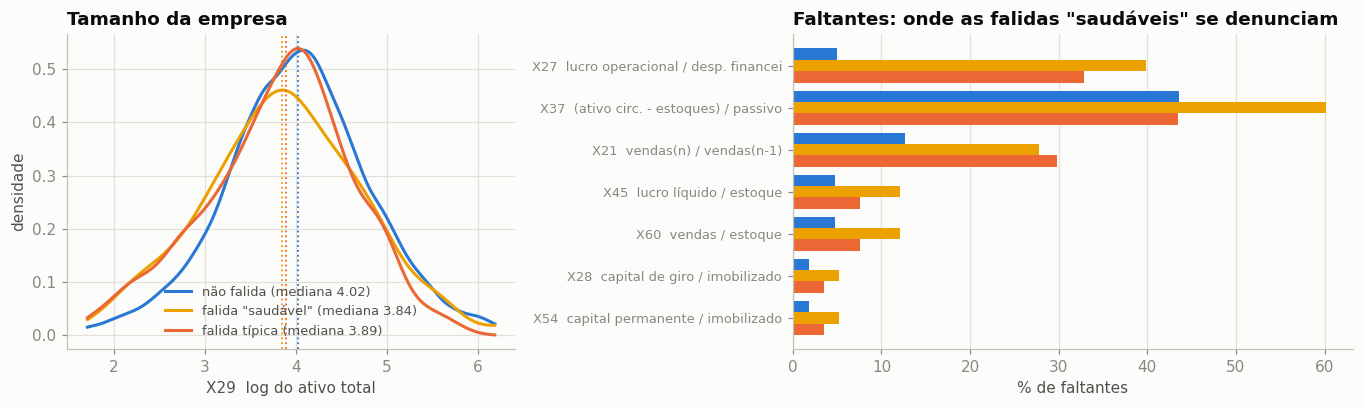

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={'width_ratios': [1, 1.25]})

# Tamanho: log do ativo total
grade = np.linspace(df['X29'].quantile(0.005), df['X29'].quantile(0.995), 200)
for gnome in ordem_g:
    x = df.loc[df['grupo'] == gnome, 'X29'].dropna()
    cor = COR_GRUPO[gnome] if gnome != 'não falida' else '#2a78d6'
    axes[0].plot(grade, stats.gaussian_kde(x)(grade), color=cor, label=f'{gnome} (mediana {x.median():.2f})')
    axes[0].axvline(x.median(), color=cor, linestyle=':', linewidth=1.2)
axes[0].set_xlabel('X29  log do ativo total')
axes[0].set_ylabel('densidade')
axes[0].set_title('Tamanho da empresa')
axes[0].legend(fontsize=8.5)

# Faltantes: variáveis com maior diferença entre falidas "saudáveis" e não falidas
na_g = df.groupby('grupo')[VARS].apply(lambda g: g.isna().mean() * 100).T[ordem_g]
top_na = (na_g['falida "saudável"'] - na_g['não falida']).sort_values(ascending=False).index[:7]
y = np.arange(len(top_na))
alt = 0.27
for k, gnome in enumerate(ordem_g):
    axes[1].barh(y + (k - 1) * alt, na_g.loc[top_na, gnome], height=alt,
                 color=COR_GRUPO[gnome] if gnome != 'não falida' else '#2a78d6', label=gnome)
axes[1].set_yticks(y, [f'{v}  {DIC[v][:34]}' for v in top_na], fontsize=8.5)
axes[1].invert_yaxis()
axes[1].set_xlabel('% de faltantes')
axes[1].set_title('Faltantes: onde as falidas "saudáveis" se denunciam')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()

### 9.4 Os modelos encontram essas empresas?

Usa as previsões salvas pelos notebooks 03 e 04, sempre fora da amostra: validação cruzada no treino e o teste. O limiar é o que dá 5% de falsos positivos em cada conjunto, o mesmo critério do recall dos slides. A célula só roda se os arquivos de previsão existirem.

In [34]:
from sklearn.metrics import roc_curve

if Path('resultados/prev_mlp.npz').exists() and Path('resultados/prev_logistica.npz').exists():
    from sklearn.model_selection import train_test_split
    # mesma base e mesma divisão dos notebooks 03 a 06: sem duplicadas dentro de cada arquivo, infinitos como
    # faltantes, alvo multiclasse y, treino 80% / teste 20% estratificado por y, semente 42
    base_m = pd.concat([bases[k].drop_duplicates().assign(arquivo=k) for k in ANOS], ignore_index=True)
    base_m[VARS] = base_m[VARS].replace([np.inf, -np.inf], np.nan)
    base_m['y'] = np.where(base_m['class'] == 1, 6 - base_m['arquivo'], 0).astype(int)
    tr, te = (d.reset_index(drop=True) for d in train_test_split(
        base_m, test_size=0.20, stratify=base_m['y'], random_state=42))
    assert (np.load('resultados/prev_y.npz')['y_te'] == te['y'].values).all(), 'divisão diferente da dos notebooks 03-06'
    prev = {'MLP': np.load('resultados/prev_mlp.npz'), 'Regressão logística': np.load('resultados/prev_logistica.npz')}
    linhas = []
    for nome_c, (base, chave) in {'validação (fora do fold)': (tr, 'P_oof'), 'teste': (te, 'P_te')}.items():
        saudavel = (base['X1'] > 0) & (base['X3'] > 0) & (base['X4'] > 1.2) & (base['X2'] < 0.6)
        f = base['class'] == 1
        for nome_m, P in prev.items():
            p = 1 - P[chave][:, 0]  # P(faliu) = 1 - P(não faliu)
            fpr, tpr, thr = roc_curve(base['class'], p)
            lim = thr[np.searchsorted(fpr, 0.05, side='right') - 1]
            for g, m in [('falidas "saudáveis"', f & saudavel), ('falidas típicas', f & ~saudavel)]:
                linhas.append({'conjunto': nome_c, 'modelo': nome_m, 'grupo': g, 'n': int(m.sum()),
                               'recall a 5% de FP (%)': (p[m] >= lim).mean() * 100,
                               'P(faliu) mediana': np.median(p[m])})
    rec = pd.DataFrame(linhas).set_index(['conjunto', 'modelo', 'grupo'])
    display(rec.round(3))
else:
    print('Previsões não encontradas: rode os notebooks 03 e 04 antes desta célula.')

n  recall a 5% de FP (%)  P(faliu) mediana
conjunto                 modelo              grupo                                                             
validação (fora do fold) MLP                 falidas "saudáveis"   330                 37.273             0.097
                                             falidas típicas      1336                 63.323             0.267
                         Regressão logística falidas "saudáveis"   330                  0.303             0.028
                                             falidas típicas      1336                 33.683             0.093
teste                    MLP                 falidas "saudáveis"    76                 42.105             0.111
                                             falidas típicas       341                 61.877             0.260
                         Regressão logística falidas "saudáveis"    76                  1.316             0.028
                                             falidas típicas       341                 34.018             0.102

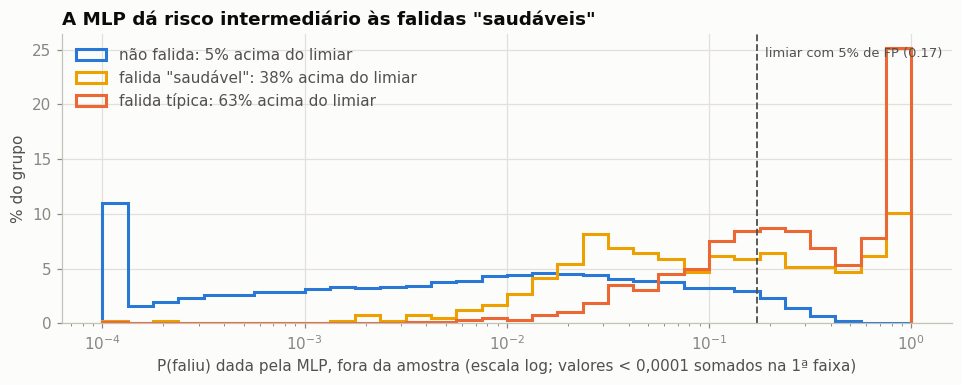

In [35]:
if Path('resultados/prev_mlp.npz').exists():
    oof = pd.concat([tr.assign(p=1 - prev['MLP']['P_oof'][:, 0]), te.assign(p=1 - prev['MLP']['P_te'][:, 0])],
                    ignore_index=True)
    s_oof = (oof['X1'] > 0) & (oof['X3'] > 0) & (oof['X4'] > 1.2) & (oof['X2'] < 0.6)
    oof['grupo'] = np.select([oof['class'] == 0, (oof['class'] == 1) & s_oof],
                             ['não falida', 'falida "saudável"'], default='falida típica')
    fpr, tpr, thr = roc_curve(oof['class'], oof['p'])
    lim = thr[np.searchsorted(fpr, 0.05, side='right') - 1]

    fig, ax = plt.subplots(figsize=(9, 3.6))
    bins = np.logspace(-4, 0, 33)
    for gnome in ordem_g:
        pg = oof.loc[oof['grupo'] == gnome, 'p'].clip(1e-4, 1)
        acima = (pg >= lim).mean() * 100
        ax.hist(pg, bins=bins, weights=np.full(len(pg), 100 / len(pg)), histtype='step', linewidth=2,
                color=COR_GRUPO[gnome] if gnome != 'não falida' else '#2a78d6',
                label=f'{gnome}: {acima:.0f}% acima do limiar')
    ax.axvline(lim, color=TINTA2, linestyle='--', linewidth=1.2)
    ax.text(lim * 1.1, ax.get_ylim()[1] * 0.92, f'limiar com 5% de FP ({lim:.2f})', fontsize=8.5, color=TINTA2)
    ax.set_xscale('log')
    ax.set_xlabel('P(faliu) dada pela MLP, fora da amostra (escala log; valores < 0,0001 somados na 1ª faixa)')
    ax.set_ylabel('% do grupo')
    ax.set_title('A MLP dá risco intermediário às falidas "saudáveis"')
    ax.legend(loc='upper left')
    plt.tight_layout()

### Conclusões da seção 9

- **Sim, há falidas com bons indicadores, variável por variável.** Em cada um dos 12 indicadores, de 19% a 29% das falidas tinham valor melhor do que a mediana das não falidas, e de 8% a 14% eram melhores do que 3 em cada 4 empresas que não faliram. Sem relação nenhuma, seriam 50% e 25%. As variáveis de lucro sobre passivo (X26, X16) deixam menos falidas do lado "bom" (19%); capital de giro (X3) deixa mais (29%).
- **Isso é mais comum longe da falência**: na maioria das variáveis, a fração de falidas do lado "bom" cai do ano 2 (4 anos antes) para o ano 5 (1 ano antes), por exemplo de 25% para 14% em X26. A piora só aparece nos balanços mais próximos do desfecho.
- **O risco cai a cada regra cumprida, mas não zera**: a taxa de falência vai de 13,8% nas empresas que não cumprem nenhuma das 4 regras para 1,9% nas que cumprem todas. Só que esse grupo é enorme (21 mil empresas, metade da base), e por isso ainda reúne 407 falidas, 19,5% de todas.
- **No mapa de rentabilidade × endividamento**, essas falidas ficam no meio da massa de não falidas: nenhum corte nos indicadores as separa sem marcar milhares de empresas sãs.
- **O que as denuncia são os faltantes, não o tamanho**: o tamanho (log do ativo) é só um pouco menor (mediana 3,84 contra 4,02). Já os faltantes são muito mais frequentes: X27 (lucro operacional / despesas financeiras) falta em 40% delas contra 5% das não falidas, e X21 (crescimento de vendas) em 28% contra 13%. Balanço incompleto é um sinal de risco que o modelo final, sem indicadores de faltante, não usa.
- **Os modelos encontram menos delas**: com 5% de falsos positivos, a MLP detecta 38% dessas falidas (37% na validação e 42% no teste), contra 63% das falidas típicas; a maioria recebe risco intermediário, entre 1% e 30%. A regressão logística praticamente não detecta nenhuma (0% a 1%). Parte do sinal da MLP vem de combinações entre variáveis, não dos indicadores isolados. É o limite de prever falência só pelo balanço.

## Conclusões

**Estrutura e qualidade**
- Não há valores infinitos. Há de 60 a 90 linhas duplicadas por arquivo (~1%) e nenhuma duplicata exata entre arquivos. Vale remover as duplicadas dentro de cada ano antes de separar treino/teste, para não vazar linhas idênticas.
- X37 tem ~44% de faltantes em todos os anos — candidata a descarte. X21 (crescimento de vendas) falta em 23–31% nos anos 1–2 e só ~2% nos anos 4–5.
- **O faltante é informativo**: X27 (lucro operacional / despesas financeiras) falta em 34% das falidas contra 5% das não falidas; X21 em 29% contra 13%. Para a rede, imputar (mediana) **e** criar indicadores de faltante para essas variáveis.

**Distribuições**
- As 64 razões têm caudas extremas (curtose na casa de 10⁴ e valores de ±10⁶), por denominadores próximos de zero. Antes da rede: winsorizar (p1–p99) ou log com sinal / `QuantileTransformer`, depois padronizar. Padronizar sem isso deixa quase todo o sinal comprimido perto de zero.

**Poder discriminante e redundância**
- Os indicadores de rentabilidade e endividamento são os mais fortes (AUC univariada ≈ 0,28–0,33, sempre "menor → mais falência"): X26, X16, X13, X46, X12, X24.
- Há 10 grupos de variáveis praticamente redundantes (|ρ| ≥ 0,95). O maior junta X1, X7, X11, X14, X18 (lucro / ativo total). Também X2, X8, X10, X17 (estrutura de capital) e X32, X33, X52, X62, X63 (prazo do passivo de curto prazo). Para a rede isso não impede o treino, mas é útil para interpretar e para reduzir dimensão.

**Estabilidade**
- **Variável resposta**: a taxa de falência sobe de 3,9% (ano 1) para 6,9% (ano 5). Cada horizonte tem sua própria prevalência, o que pesa na calibração e no limiar de decisão.
- **Distribuição (PSI vs ano 1)**: 42 variáveis estáveis (PSI < 0,10), 21 com mudança moderada e 1 relevante (X21). A mudança de X21 vem principalmente da **queda na taxa de faltantes**: o PSI inclui um bin de faltantes. Mesmo só entre não falidas o PSI continua alto, então não é efeito de composição.
- **A deriva está concentrada entre o ano 1 e os demais**: o PSI consecutivo 1→2 é de 0,10–0,18 nas variáveis de rentabilidade, mas 2→3, 3→4 e 4→5 ficam em ~0,01. Os anos 2–5 são estáveis entre si. Uma explicação provável é que o arquivo `1year.arff` foi filtrado na origem: o cabeçalho do ARFF registra `SubsetByExpression ... not ismissing(ATT20)`. Sem faltantes em X20, a população do ano 1 é diferente.
- **Relação com a resposta**: o poder discriminante muda bastante entre horizontes. Ele cai no ano 2 e cresce até o ano 5 (|AUC − 0,5| de ~0,12–0,22 para ~0,25–0,30), como esperado perto da falência. X15 e X41 (passivo / lucro) **invertem a direção**: AUC 0,55 no ano 1 e 0,33 no ano 5.

**Falidas com bons indicadores (seção 9)**
- Em cada indicador, de 19% a 29% das falidas tinham valor melhor do que a mediana das não falidas, e 19,5% passavam numa regra contábil simples de boa saúde (mais comum 4 a 5 anos antes da falência). Cumprir as 4 regras derruba a taxa de falência de 13,8% para 1,9%, mas não a zera. O que diferencia essas falidas são os faltantes (X27 falta em 40% delas), e os modelos detectam menos delas: é o limite de prever falência só pelo balanço.

**Implicações para a modelagem**
1. Como a relação X → y muda com o horizonte, um modelo único que empilha os 5 anos precisa receber o horizonte como entrada (ex.: one-hot do `ano`). A alternativa é um modelo por horizonte. A comparação natural é treinar em um ano e avaliar nos outros (estabilidade fora da amostra).
2. Separar treino/validação/teste **estratificado pela classe** dentro de cada ano. Usar AUC-ROC e PR-AUC como métricas e *class weights* ou *focal loss* para o desbalanceamento.
3. Pré-processamento: tirar as duplicadas, descartar X37, imputar com indicadores de faltante (X21, X27, X45, X60…) e transformar as caudas antes de padronizar.
4. A tabela `resumo_variaveis.csv` (gerada acima) consolida, por variável, faltantes, AUC, PSI, KS e redundância para guiar a seleção.
